In [ ]:
def show(words):
    """Print words like a set, keeping their order. Empty -> set()"""
    return "{" + ", ".join(f"'{w}'" for w in words) + "}" if words else "set()"

ambiguous_word = "pen"

senses = {
    "Writing Pen": "an instrument used for writing with ink",
    "Playpen": "an enclosed area where a baby or child can play safely",
    "Animal Pen": "an enclosed area where animals are kept",
}

sentence = "The little toy box and child play in the room"
stopwords = {"the", "and", "in", "a", "an", "to", "of", "is"}

# context words (ordered, unique, stopwords removed)
context_words = []
for w in sentence.lower().split():
    if w not in stopwords and w not in context_words:
        context_words.append(w)

print("1. AMBIGUOUS WORD")
print("Ambiguous word:", ambiguous_word)

print("\n2. SENSES WITH DEFINITIONS")
for sense, definition in senses.items():
    print(f"{sense} : {definition}")

print("\n3. CONTEXT WORDS")
print(show(context_words[:5])[:-1] + ", ...}")

print("\n4. OVERLAP COUNT")
best_sense, max_overlap = None, -1

for sense, definition in senses.items():
    def_words = []
    for w in definition.lower().split():
        if w not in def_words:
            def_words.append(w)

    shared = [w for w in def_words if w in context_words]
    overlap = len(shared)

    print(f"\n {sense}")
    print("Definition words:", show(def_words))
    print("Shared words:", show(shared))
    print("Overlap count:", overlap)

    if overlap > max_overlap:
        max_overlap, best_sense = overlap, sense

print("\n5. SELECTED SENSE")
print("Sense with maximum overlap:", best_sense)
print("Maximum overlap:", max_overlap)

1. AMBIGUOUS WORD
Ambiguous word: pen

2. SENSES WITH DEFINITIONS
Writing Pen : an instrument used for writing with ink
Playpen : an enclosed area where a baby or child can play safely
Animal Pen : an enclosed area where animals are kept

3. CONTEXT WORDS
{'little', 'toy', 'box', 'child', 'play', ...}

4. OVERLAP COUNT

 Writing Pen
Definition words: {'an', 'instrument', 'used', 'for', 'writing', 'with', 'ink'}
Shared words: set()
Overlap count: 0

 Playpen
Definition words: {'an', 'enclosed', 'area', 'where', 'a', 'baby', 'or', 'child', 'can', 'play', 'safely'}
Shared words: {'child', 'play'}
Overlap count: 2

 Animal Pen
Definition words: {'an', 'enclosed', 'area', 'where', 'animals', 'are', 'kept'}
Shared words: set()
Overlap count: 0

5. SELECTED SENSE
Sense with maximum overlap: Playpen
Maximum overlap: 2


Total words after preprocessing: 44825

Top 15 most frequent words:
said: 484
upon: 465
holmes: 413
one: 344
would: 324
could: 286
man: 280
little: 267
mr: 262
see: 216
may: 208
us: 182
must: 171
shall: 171
think: 168


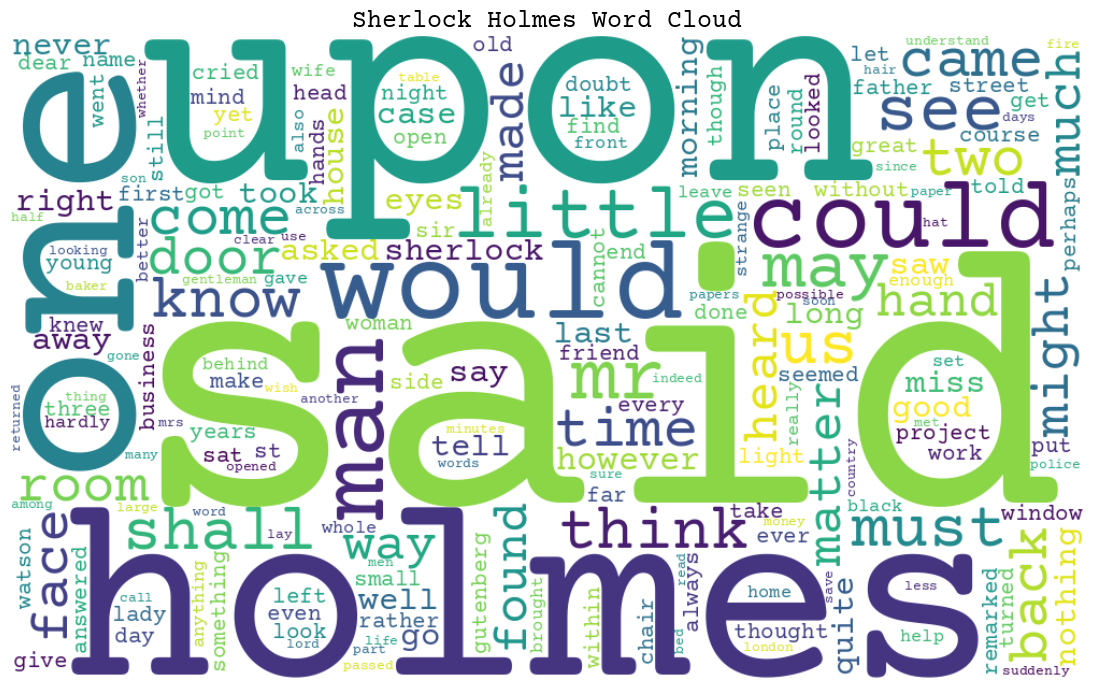

In [ ]:

!pip -q install wordcloud requests nltk matplotlib

import requests
import nltk
import string
import matplotlib.pyplot as plt
from collections import Counter
from wordcloud import WordCloud
from matplotlib.font_manager import FontProperties

# Download required NLTK stopwords
nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords

# Step 1: Download Sherlock Holmes dataset
url = "https://www.gutenberg.org/cache/epub/1661/pg1661.txt"
response = requests.get(url, timeout=30)
response.raise_for_status()
text = response.text

# Step 2: Convert text to lowercase
text = text.lower()

# Step 3: Remove punctuation
text = text.translate(str.maketrans("", "", string.punctuation))

# Step 4: Tokenize text into words
words = text.split()

# Step 5: Remove stopwords and non-alphabetic words
stop_words = set(stopwords.words("english"))
filtered_words = [
    word for word in words
    if word not in stop_words and word.isalpha()
]

# Step 6: Calculate word frequencies
word_counts = Counter(filtered_words)

print("Total words after preprocessing:", len(filtered_words))
print("\nTop 15 most frequent words:")
for word, count in word_counts.most_common(15):
    print(f"{word}: {count}")

# Step 7: Download a Courier-style font for Google Colab
font_url = (
    "https://raw.githubusercontent.com/google/fonts/"
    "main/ofl/courierprime/CourierPrime-Regular.ttf"
)
font_path = "/content/CourierPrime-Regular.ttf"

font_response = requests.get(font_url, timeout=30)
font_response.raise_for_status()

with open(font_path, "wb") as font_file:
    font_file.write(font_response.content)

courier_font = FontProperties(fname=font_path)

# Step 8: Generate Word Cloud using Courier-style font
wordcloud = WordCloud(
    width=1000,
    height=600,
    background_color="white",
    colormap="viridis",
    max_words=200,
    font_path=font_path,
    collocations=False
).generate_from_frequencies(word_counts)

plt.figure(figsize=(12, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.title(
    "Sherlock Holmes Word Cloud",
    fontproperties=courier_font,
    fontsize=18
)
plt.axis("off")
plt.tight_layout()
plt.show()

# Step 9: Generate Horizontal Bar Graph using Bigram Frequency Analysis
!pip -q install plotly

import plotly.express as px
import pandas as pd
from nltk.util import bigrams
from collections import Counter

# Calculate bigram frequencies
bigram_counts = Counter(bigrams(filtered_words))

# Select the top 30 bigrams
top_bigrams = bigram_counts.most_common(30)

bar_data = pd.DataFrame([
    {
        "Bigram": " ".join(bigram),
        "Frequency": count
    }
    for bigram, count in top_bigrams
])

# Create Horizontal Bar Graph
fig = px.bar(
    bar_data.sort_values("Frequency", ascending=True),
    x="Frequency",
    y="Bigram",
    orientation="h",
    color="Frequency",
    color_continuous_scale="Viridis",
    title="Horizontal Bar Graph: Top 30 Bigram Frequencies in Sherlock Holmes"
)

# Customize layout and fonts
fig.update_layout(
    title=dict(
        text="Horizontal Bar Graph: Top 30 Bigram Frequencies in Sherlock Holmes",
        font=dict(family="monospace", size=24),
        x=0.5,
        xanchor="center"
    ),
    font=dict(family="monospace", size=15),
    xaxis_title="Frequency",
    yaxis_title="Bigrams",
    width=1200,
    height=900
)

fig.update_traces(
    hoverlabel=dict(font=dict(family="monospace", size=16))
)

fig.show()